In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

In [2]:
df = pd.read_csv(r"C:\Users\HP\Downloads\archive\uber.csv")
print(df.head())


   Unnamed: 0                            key  fare_amount  \
0    24238194    2015-05-07 19:52:06.0000003          7.5   
1    27835199    2009-07-17 20:04:56.0000002          7.7   
2    44984355   2009-08-24 21:45:00.00000061         12.9   
3    25894730    2009-06-26 08:22:21.0000001          5.3   
4    17610152  2014-08-28 17:47:00.000000188         16.0   

           pickup_datetime  pickup_longitude  pickup_latitude  \
0  2015-05-07 19:52:06 UTC        -73.999817        40.738354   
1  2009-07-17 20:04:56 UTC        -73.994355        40.728225   
2  2009-08-24 21:45:00 UTC        -74.005043        40.740770   
3  2009-06-26 08:22:21 UTC        -73.976124        40.790844   
4  2014-08-28 17:47:00 UTC        -73.925023        40.744085   

   dropoff_longitude  dropoff_latitude  passenger_count  
0         -73.999512         40.723217                1  
1         -73.994710         40.750325                1  
2         -73.962565         40.772647                1  
3         

In [11]:
df = df.drop(columns=["key", "Unnamed: 0", "pickup_datetime"], errors="ignore")
df = df.dropna()

print("\nSTEP 2: After Preprocessing")
print(df.head())
print("Shape:", df.shape)


STEP 2: After Preprocessing
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  
0         40.723217                1    19  
1         40.750325                1    20  
2         40.772647                1    21  
3         40.803349                3     8  
4         40.761247                5    17  
Shape: (199999, 7)


In [12]:
Q1 = df["fare_amount"].quantile(0.25)
Q3 = df["fare_amount"].quantile(0.75)

IQR = Q3 - Q1

print("\nSTEP 3: Outlier Detection")
print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)

df = df[
    (df["fare_amount"] >= Q1 - 1.5 * IQR) &
    (df["fare_amount"] <= Q3 + 1.5 * IQR)
]

print("\nAfter Removing Outliers:")
print(df.head())
print("Shape:", df.shape)



STEP 3: Outlier Detection
Q1: 6.0
Q3: 12.5
IQR: 6.5

After Removing Outliers:
   fare_amount  pickup_longitude  pickup_latitude  dropoff_longitude  \
0          7.5        -73.999817        40.738354         -73.999512   
1          7.7        -73.994355        40.728225         -73.994710   
2         12.9        -74.005043        40.740770         -73.962565   
3          5.3        -73.976124        40.790844         -73.965316   
4         16.0        -73.925023        40.744085         -73.973082   

   dropoff_latitude  passenger_count  hour  
0         40.723217                1    19  
1         40.750325                1    20  
2         40.772647                1    21  
3         40.803349                3     8  
4         40.761247                5    17  
Shape: (182833, 7)



STEP 4: Correlation Matrix
                   fare_amount  pickup_longitude  pickup_latitude  \
fare_amount           1.000000          0.000367         0.002618   
pickup_longitude      0.000367          1.000000        -0.812047   
pickup_latitude       0.002618         -0.812047         1.000000   
dropoff_longitude    -0.002413          0.835950        -0.767103   
dropoff_latitude      0.000589         -0.850574         0.684558   
passenger_count       0.012618         -0.000751        -0.001604   
hour                 -0.013219          0.003544        -0.004675   

                   dropoff_longitude  dropoff_latitude  passenger_count  \
fare_amount                -0.002413          0.000589         0.012618   
pickup_longitude            0.835950         -0.850574        -0.000751   
pickup_latitude            -0.767103          0.684558        -0.001604   
dropoff_longitude           1.000000         -0.913949         0.000203   
dropoff_latitude           -0.913949        

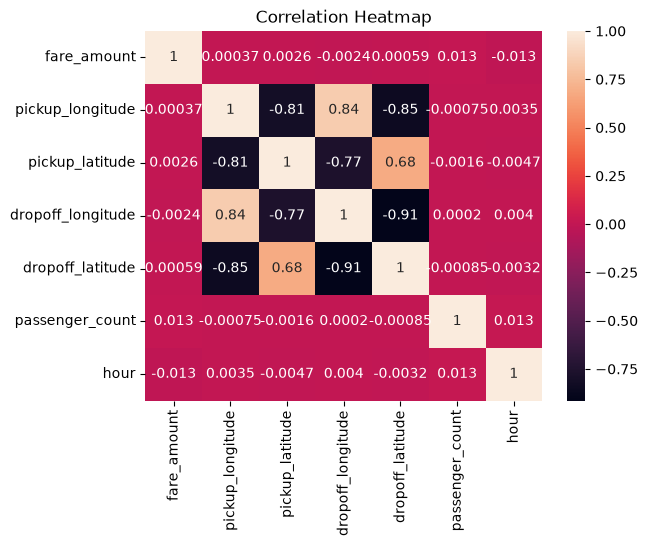

In [13]:
print("\nSTEP 4: Correlation Matrix")
print(df.corr())

sns.heatmap(df.corr(), annot=True)
plt.title("Correlation Heatmap")
plt.show()

In [14]:
# Split input and output
X = df.drop("fare_amount", axis=1)
y = df["fare_amount"]

# Split training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("\nTraining and Testing Data")
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)


# Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)

pred1 = lr.predict(X_test)

print("\nLinear Regression")
print("Predicted Values:", pred1[:5])
print("R2:", r2_score(y_test, pred1))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred1)))


# Random Forest Regression
rf = RandomForestRegressor(n_estimators=50, random_state=42)
rf.fit(X_train, y_train)

pred2 = rf.predict(X_test)

print("\nRandom Forest Regression")
print("Predicted Values:", pred2[:5])
print("R2:", r2_score(y_test, pred2))
print("RMSE:", np.sqrt(mean_squared_error(y_test, pred2)))



Training and Testing Data
X_train: (146266, 6)
X_test: (36567, 6)

Linear Regression
Predicted Values: [8.86757075 8.84907144 8.913602   8.90467633 9.03348592]
R2: 0.0001311381658155586
RMSE: 4.1365246539843366

Random Forest Regression
Predicted Values: [ 6.01  17.778  8.242 15.642  7.196]
R2: 0.7173734683926842
RMSE: 2.199229536911472
